# 重庆市开州区汉丰湖周边 5km Sentinel-2 遥感影像 NDVI 计算、统计与可视化

- **数据源**：`COPERNICUS/S2_SR_HARMONIZED`（Sentinel-2 L2A 地表反射率，已统一处理基线，DN×1e-4 即反射率）
- **时间**：2024-06-01 ~ 2024-09-30（夏季，植被生长旺季）
- **去云**：SCL 场景分类层（QA60 波段自 ESA 处理基线 04.00 起已停止更新，2024 年多数景全为 0，继续用 QA60 掩膜等于没有去云）
- **指标**：NDVI = (B8 − B4) / (B8 + B4)，先中值合成再计算，10 m 分辨率
- **范围**：汉丰湖主湖面中心点（108.432, 31.190）5 km 缓冲区

In [1]:
import os
import ee
import geemap

# 需要代理才能访问 GEE 的话，改成自己的端口；直连时两行可注释掉
os.environ.setdefault('HTTP_PROXY', 'http://127.0.0.1:7897')
os.environ.setdefault('HTTPS_PROXY', 'http://127.0.0.1:7897')

# project 换成自己注册的 GEE 项目 ID
PROJECT = 'vaulted-dolphin-512908-p9'

# 检查并完成认证与初始化
try:
    ee.Initialize(project=PROJECT)
    print("GEE 初始化成功！")
except Exception:
    print("未检测到有效凭证，正在发起认证...")
    ee.Authenticate()
    ee.Initialize(project=PROJECT)
    print("认证并初始化成功！")

GEE 初始化成功！


In [2]:
# 1. 研究区定义（汉丰湖主湖面中心点 + 5km 缓冲圈）
hanfeng_center = ee.Geometry.Point([108.432, 31.190])  # 湖面中心，已按 NDVI 影像核对
roi = hanfeng_center.buffer(5000)                      # 5,000 米 = 5 km

# 2. Sentinel-2 去云函数（SCL 场景分类掩膜）
#    保留：4 植被、5 裸地、6 水体、7 未分类、11 积雪
#    掩掉：3 云影、8 中概率云、9 高概率云、10 薄云
def mask_s2_clouds(image):
    scl = image.select('SCL')
    good = (scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6))
            .Or(scl.eq(7)).Or(scl.eq(11)))
    return image.updateMask(good).divide(10000)      # SR 反射率缩放 1e-4

# 3. 影像筛选与夏季中值合成
s2_collection = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(roi)
    .filterDate('2024-06-01', '2024-09-30')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60))
    .map(mask_s2_clouds)
)

n_scenes = s2_collection.size().getInfo()
composite = s2_collection.median().clip(roi)
print(f"[OK] 参与合成的影像数量：{n_scenes} 景")
print("[OK] 影像筛选与 5km 区域去云中值合成完成！")

[OK] 参与合成的影像数量：12 景
[OK] 影像筛选与 5km 区域去云中值合成完成！


In [3]:
# 1. 计算 NDVI 指标：(近红外 B8 - 红光 B4) / (近红外 B8 + 红光 B4)
ndvi = composite.normalizedDifference(['B8', 'B4']).rename('NDVI')

# 2. 统计 5km 范围内的 NDVI（scale 与导出保持一致：10 m，并固定 UTM 49N 投影）
print("正在从 GEE 云端统计 5km 范围内的指标数据，请稍候...")
reducer = (ee.Reducer.mean()
           .combine(ee.Reducer.minMax(), sharedInputs=True)
           .combine(ee.Reducer.stdDev(), sharedInputs=True)
           .combine(ee.Reducer.percentile([10, 50, 90]), sharedInputs=True))
stats = ndvi.reduceRegion(
    reducer=reducer,
    geometry=roi,
    scale=10,
    crs='EPSG:32649',   # UTM 49N，避免经纬度像元非等比
    maxPixels=1e9
).getInfo()

# 3. 采样典型地物点（坐标逐个对过 NDVI 影像；用 30m 窗口均值降低单像元噪声）
pts_fc = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([108.432, 31.190]).buffer(15), {'type': '汉丰湖水面'}),
    ee.Feature(ee.Geometry.Point([108.452, 31.187]).buffer(15), {'type': '汉丰湖水面(东)'}),
    ee.Feature(ee.Geometry.Point([108.435, 31.210]).buffer(15), {'type': '湖周山林'}),
    ee.Feature(ee.Geometry.Point([108.396, 31.176]).buffer(15), {'type': '开州城区建设用地'}),
    ee.Feature(ee.Geometry.Point([108.408, 31.170]).buffer(15), {'type': '开州城区建设用地(2)'})
])
sample_vals = ndvi.reduceRegions(
    collection=pts_fc, reducer=ee.Reducer.mean(), scale=10, crs='EPSG:32649'
).getInfo()

# 4. 控制台打印格式化统计结果
print("=" * 62)
print("【重庆市开州区汉丰湖周边 5km NDVI 植被指数统计结果】")
print("=" * 62)
print(f"  * 区域 NDVI 平均值 (Mean)  : {stats['NDVI_mean']:.4f}")
print(f"  * 区域 NDVI 最大值 (Max)   : {stats['NDVI_max']:.4f}")
print(f"  * 区域 NDVI 最小值 (Min)   : {stats['NDVI_min']:.4f}")
print(f"  * 区域 NDVI 标准差 (StdDev): {stats['NDVI_stdDev']:.4f}")
print(f"  * 分位数 P10/P50/P90      : {stats['NDVI_p10']:.4f} / "
      f"{stats['NDVI_p50']:.4f} / {stats['NDVI_p90']:.4f}")
print("-" * 62)
print("【典型地物采样点 NDVI 实测值（30m 窗口均值）】")
for feat in sample_vals['features']:
    land_type = feat['properties']['type']
    val = feat['properties'].get('mean')
    print(f"  * {land_type} : NDVI = {val:.4f}" if val is not None
          else f"  * {land_type} : NDVI = 无有效观测")
print("=" * 62)

正在从 GEE 云端统计 5km 范围内的指标数据，请稍候...
【重庆市开州区汉丰湖周边 5km NDVI 植被指数统计结果】
  * 区域 NDVI 平均值 (Mean)  : 0.5180
  * 区域 NDVI 最大值 (Max)   : 0.9088
  * 区域 NDVI 最小值 (Min)   : -0.8091
  * 区域 NDVI 标准差 (StdDev): 0.3706
  * 分位数 P10/P50/P90      : 0.0743 / 0.6602 / 0.8320
--------------------------------------------------------------
【典型地物采样点 NDVI 实测值（30m 窗口均值）】
  * 汉丰湖水面 : NDVI = -0.5279
  * 汉丰湖水面(东) : NDVI = -0.7014
  * 湖周山林 : NDVI = 0.8244
  * 开州城区建设用地 : NDVI = 0.3693
  * 开州城区建设用地(2) : NDVI = 0.2431


In [4]:
# 聚焦汉丰湖 5km 范围
Map = geemap.Map(center=[31.190, 108.432], zoom=12)

ndvi_vis = {
    'min': -0.1,
    'max': 0.85,
    'palette': [
        '#0000FF', '#FFFFFF', '#CE7E45', '#DF923D', '#F1B555', '#FCD163',
        '#99B718', '#74A901', '#66A000', '#529400', '#3E8601', '#207401',
        '#056201', '#004C00'
    ]
}

# 添加图层
Map.add_layer(composite, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.25},
              'Sentinel-2 真彩色 (RGB)')
Map.add_layer(ndvi, ndvi_vis, 'Sentinel-2 NDVI')
Map.add_layer(roi, {'color': 'red', 'fillColor': '#00000000'}, '5km 研究区边界')
Map.add_layer(pts_fc, {'color': 'yellow', 'fillColor': '#00000000'}, '典型地物采样点')
Map.add_colorbar(vis_params=ndvi_vis, label="NDVI Index")

# 显示地图（点击地图任意位置可实时探针查询该点数值）
Map

Map(center=[31.19, 108.432], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprigh…

正在下载 10m 分辨率的高清 NDVI 影像到: data/HanfengLake_5km_NDVI_10m.tif ...
Generating URL ...
Please wait ...
Data downloaded to d:\git仓库\李佳鹏-11.2-二次作业\data\HanfengLake_5km_NDVI_10m.tif
[SUCCESS] 影像下载完成！
[SUCCESS] 静态图已保存：data/HanfengLake_5km_NDVI_map.png
--------------------------------------------------------------
【NDVI 分级面积占比（5km 圆内有效像元）】
  * 水体/阴影   NDVI < 0        :   8.5 %
  * 低植被   0 <= NDVI < 0.3     :  11.9 %
  * 中植被   0.3 <= NDVI < 0.6   :  23.1 %
  * 高植被      NDVI >= 0.6      :  56.5 %
  * 有效像元数：101528 个


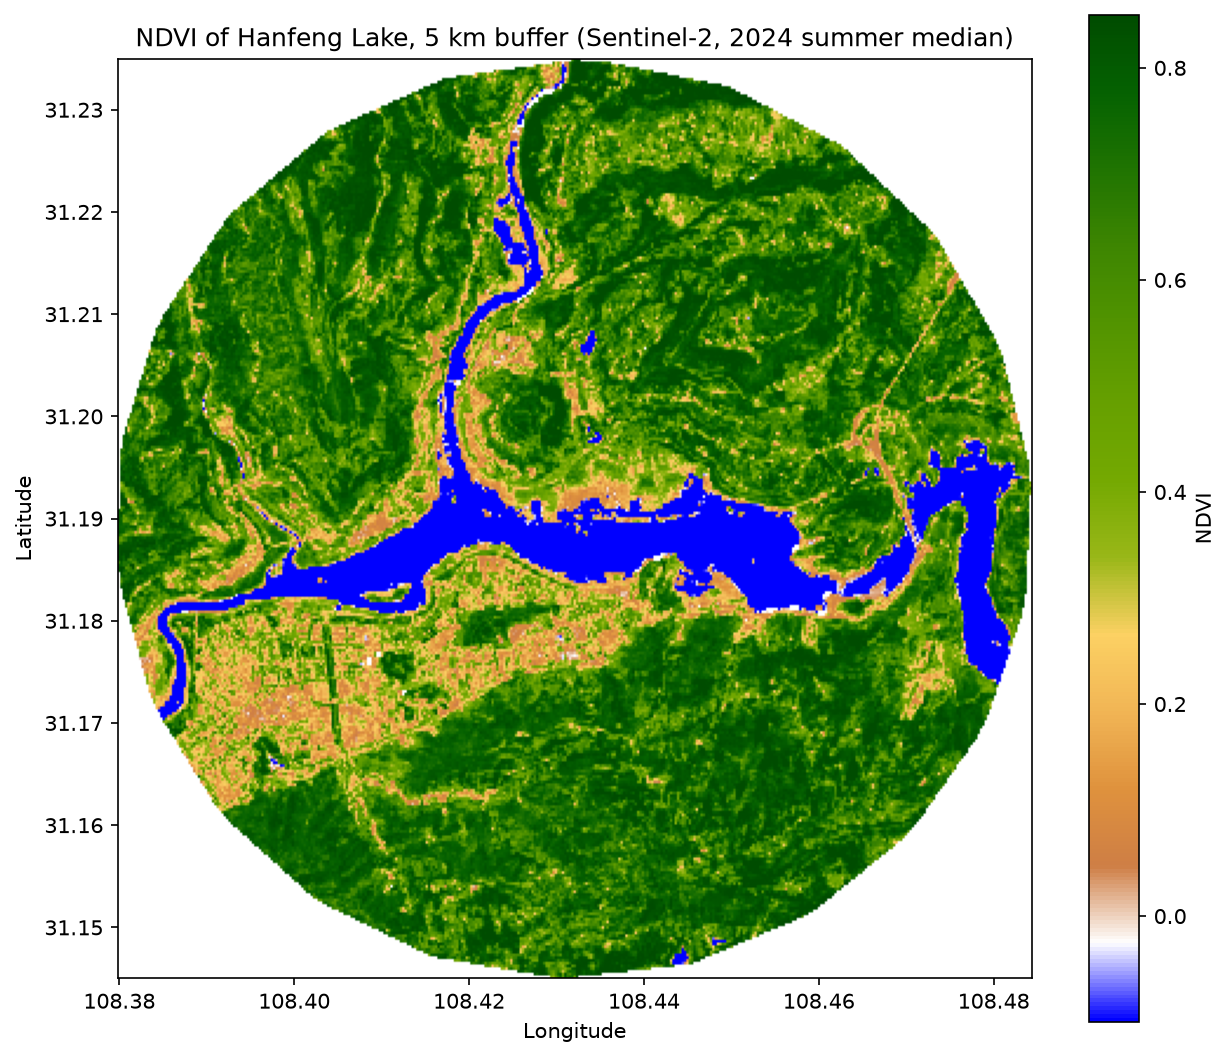

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

os.makedirs('data', exist_ok=True)

# 1. 下载 10m NDVI 影像（指定 UTM 49N，像元才是真正的 10m x 10m 等比网格）
output_file = 'data/HanfengLake_5km_NDVI_10m.tif'
print(f"正在下载 10m 分辨率的高清 NDVI 影像到: {output_file} ...")
geemap.ee_export_image(ndvi, filename=output_file, scale=10, region=roi,
                       crs='EPSG:32649', file_per_band=False)
print("[SUCCESS] 影像下载完成！")

# 2. 取数组画静态图（导出的 tif 是分块压缩浮点，本机没装 rasterio，改用 GEE 直接取数组）
#    注意两点：ee_to_numpy 返回的是经纬度网格（东西向像元约 25.7m、南北向约 30m），
#    并且只按外接矩形裁剪、圆外的像元取回来是 0，所以圆外要自己按经纬度算距离剔除。
arr = geemap.ee_to_numpy(ndvi, region=roi, scale=30)[:, :, 0]
b = roi.bounds().getInfo()['coordinates'][0]
xmin, xmax = min(p[0] for p in b), max(p[0] for p in b)   # 经度范围
ymin, ymax = min(p[1] for p in b), max(p[1] for p in b)   # 纬度范围
GX, GY = np.meshgrid(np.linspace(xmin, xmax, arr.shape[1]),
                     np.linspace(ymax, ymin, arr.shape[0]))
dist_m = np.hypot((GX - 108.432) * 111320 * np.cos(np.radians(31.190)),
                  (GY - 31.190) * 110574)
arr = np.where(dist_m > 5000, np.nan, arr)
arr[arr == 0] = np.nan      # 被 SCL 掩掉 / 圆外的像元取回来是 0，一并置空

cmap = LinearSegmentedColormap.from_list('ndvi', ndvi_vis['palette'])
fig, ax = plt.subplots(figsize=(8.6, 8.2), dpi=150)
im = ax.imshow(arr, extent=[xmin, xmax, ymin, ymax], cmap=cmap, vmin=-0.1, vmax=0.85)
ax.set_aspect(1.0 / np.cos(np.radians(31.190)))   # 经纬度不同尺度，按纬度校正才不会变形
ax.set_title('NDVI of Hanfeng Lake, 5 km buffer (Sentinel-2, 2024 summer median)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
fig.colorbar(im, ax=ax, shrink=0.85, label='NDVI')
fig.tight_layout()
fig.savefig('data/HanfengLake_5km_NDVI_map.png')
print("[SUCCESS] 静态图已保存：data/HanfengLake_5km_NDVI_map.png")

# 3. 按 NDVI 分级的面积占比（只统计 5km 圆内的有效像元）
v = arr[~np.isnan(arr)]
print("-" * 62)
print("【NDVI 分级面积占比（5km 圆内有效像元）】")
print(f"  * 水体/阴影   NDVI < 0        : {np.mean(v < 0) * 100:5.1f} %")
print(f"  * 低植被   0 <= NDVI < 0.3     : {np.mean((v >= 0) & (v < 0.3)) * 100:5.1f} %")
print(f"  * 中植被   0.3 <= NDVI < 0.6   : {np.mean((v >= 0.3) & (v < 0.6)) * 100:5.1f} %")
print(f"  * 高植被      NDVI >= 0.6      : {np.mean(v >= 0.6) * 100:5.1f} %")
print(f"  * 有效像元数：{v.size} 个")
